In [24]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models

In [25]:
seed = 42
tf.random.set_seed(seed)
np.random.seed(seed)

In [26]:
from pathlib import Path
train_ds, val_ds = tf.keras.utils.audio_dataset_from_directory(
    directory=str(Path.home() / ".cache" / "ml-notebooks" / "speech-commands"),
    batch_size=64,
    output_sequence_length=16000,
    seed=seed,
    validation_split=0.3,
    subset='both'
)

Found 6505 files belonging to 4 classes.
Using 4554 files for training.
Using 1951 files for validation.


In [27]:
label = np.array(train_ds.class_names)
print(label)

['follow' 'learn' 'tree' 'visual']


In [28]:
def squeeze(audio, label):
    audio = tf.squeeze(audio, axis=-1)
    return audio, label

def get_spectogram(waveform):
    spectogram = tf.signal.stft(waveform, frame_length=255, frame_step=128)
    spectogram = tf.abs(spectogram)
    spectogram = spectogram[..., tf.newaxis]
    return spectogram

def make_spectogram_ds(ds):
    return ds.map(
        map_func=lambda audio, label: (get_spectogram(audio), label),
        num_parallel_calls=tf.data.AUTOTUNE
    )

In [29]:
train_ds = train_ds.map(squeeze, tf.data.AUTOTUNE)
val_ds = val_ds.map(squeeze, tf.data.AUTOTUNE)

test_ds = val_ds.shard(num_shards=2, index=0)
val_ds = val_ds.shard(num_shards=2, index=1)

In [30]:
train_spectogram_ds = make_spectogram_ds(train_ds)
val_spectogram_ds = make_spectogram_ds(val_ds)
test_spectogram_ds = make_spectogram_ds(test_ds)

In [31]:
for spec, lab in train_spectogram_ds.take(1):
    break

input_shape = spec.shape[1:]
num_label = len(label)

In [32]:
norm_layer = layers.Normalization()
norm_layer.adapt(
    data=train_spectogram_ds.map(
        map_func=lambda spec, label: spec
    )
)

In [33]:
model = models.Sequential([
    layers.Input(input_shape),
    layers.Resizing(32, 32),
    norm_layer,
    layers.Conv2D(64, 3, activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(128, 3, activation='relu'),
    layers.MaxPooling2D(),
    layers.Dropout(0.5),
    layers.Flatten(),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(num_label)
])

In [34]:
model.summary()

Model: "sequential_5"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 resizing_8 (Resizing)       (None, 32, 32, 1)         0         
                                                                 
 normalization_2 (Normalizat  (None, 32, 32, 1)        3         
 ion)                                                            
                                                                 
 conv2d_15 (Conv2D)          (None, 30, 30, 64)        640       
                                                                 
 max_pooling2d_15 (MaxPoolin  (None, 15, 15, 64)       0         
 g2D)                                                            
                                                                 
 conv2d_16 (Conv2D)          (None, 13, 13, 128)       73856     
                                                                 
 max_pooling2d_16 (MaxPoolin  (None, 6, 6, 128)       

In [35]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy']
)

In [36]:
history = model.fit(
    train_spectogram_ds,
    validation_data=val_spectogram_ds,
    epochs=8,
    callbacks=tf.keras.callbacks.EarlyStopping(verbose=1, patience=2)
)

Epoch 1/8
72/72 [==============================] - 4s 43ms/step - loss: 0.8438 - accuracy: 0.6741 - val_loss: 0.5161 - val_accuracy: 0.8094
Epoch 2/8
72/72 [==============================] - 3s 42ms/step - loss: 0.5017 - accuracy: 0.8256 - val_loss: 0.3574 - val_accuracy: 0.8708
Epoch 3/8
72/72 [==============================] - 3s 42ms/step - loss: 0.3787 - accuracy: 0.8744 - val_loss: 0.2880 - val_accuracy: 0.8979
Epoch 4/8
72/72 [==============================] - 3s 41ms/step - loss: 0.3103 - accuracy: 0.8979 - val_loss: 0.2404 - val_accuracy: 0.9187
Epoch 5/8
72/72 [==============================] - 3s 42ms/step - loss: 0.2696 - accuracy: 0.9058 - val_loss: 0.2221 - val_accuracy: 0.9323
Epoch 6/8
72/72 [==============================] - 3s 41ms/step - loss: 0.2335 - accuracy: 0.9166 - val_loss: 0.1842 - val_accuracy: 0.9417
Epoch 7/8
72/72 [==============================] - 3s 41ms/step - loss: 0.1986 - accuracy: 0.9297 - val_loss: 0.1681 - val_accuracy: 0.9448
Epoch 8/8
72/72 [===

In [37]:
for i, (spec_batch, lab_batch) in enumerate(test_spectogram_ds):
    pred = model.predict(spec_batch)

    for j in range(len(lab_batch)):
        t = lab_batch[j].numpy()
        p = np.argmax(pred[j])

        print(f'Batch: {i}, Data: {j}: Original label: {label[t]}, Predicted label: {label[p]}')

2/2 [==============================] - 0s 7ms/step
Batch: 0, Data: 0: Original label: tree, Predicted label: tree
Batch: 0, Data: 1: Original label: learn, Predicted label: learn
Batch: 0, Data: 2: Original label: tree, Predicted label: tree
Batch: 0, Data: 3: Original label: follow, Predicted label: follow
Batch: 0, Data: 4: Original label: tree, Predicted label: tree
Batch: 0, Data: 5: Original label: follow, Predicted label: follow
Batch: 0, Data: 6: Original label: follow, Predicted label: follow
Batch: 0, Data: 7: Original label: follow, Predicted label: follow
Batch: 0, Data: 8: Original label: follow, Predicted label: follow
Batch: 0, Data: 9: Original label: learn, Predicted label: learn
Batch: 0, Data: 10: Original label: visual, Predicted label: visual
Batch: 0, Data: 11: Original label: learn, Predicted label: learn
Batch: 0, Data: 12: Original label: tree, Predicted label: tree
Batch: 0, Data: 13: Original label: follow, Predicted label: follow
Batch: 0, Data: 14: Original 

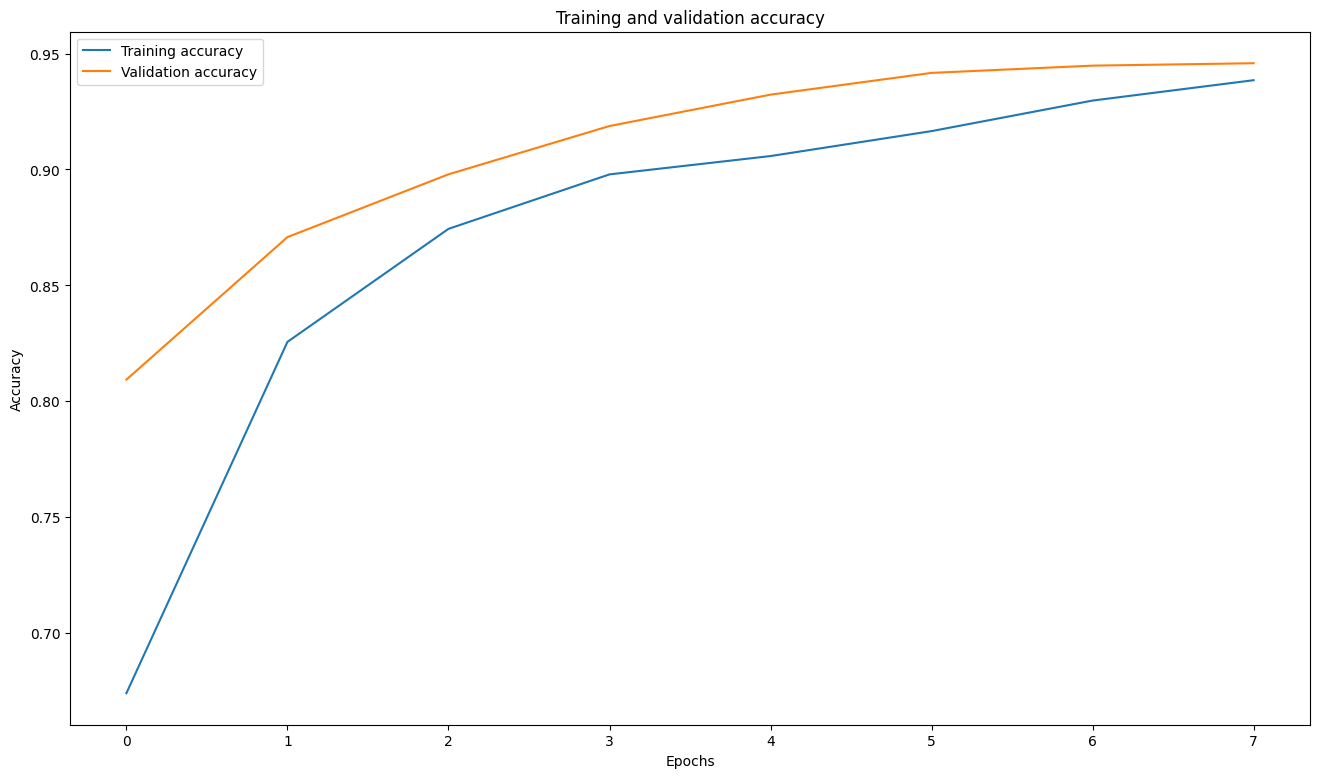

In [40]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
epoch_range = range(len(acc))

plt.figure(figsize=(16, 9))
plt.plot(epoch_range, acc, label='Training accuracy')
plt.plot(epoch_range, val_acc, label='Validation accuracy')
plt.legend()
plt.title('Training and validation accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.show()